<a href="https://colab.research.google.com/github/Abidau/PCVK_Ganjil_26-27/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Tugas Praktikum

### D1. Tugas Individu

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

NAMA = 'Naufal Abid Aurizky'
NIM = '244107020212'
BASE = '/content/drive/MyDrive/PCVK/Images/' + NIM

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

### D1 – No. 3. Global Threshold manual (T = 200)

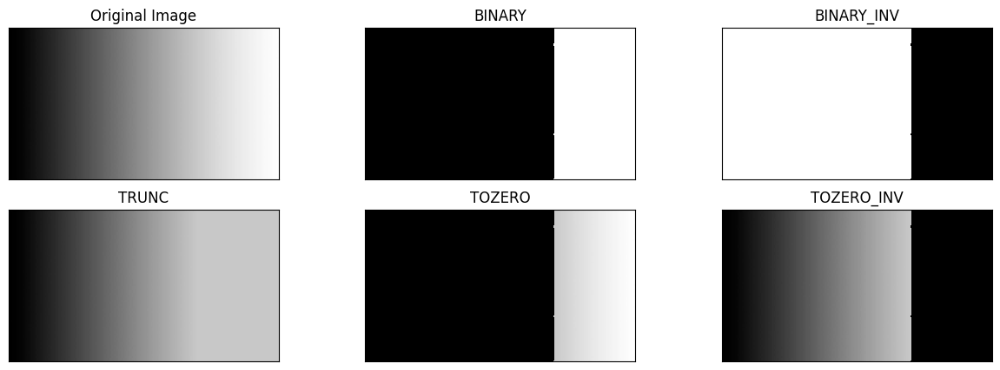

In [ ]:
def global_threshold(img, thresh, maxval=255, tipe='BINARY'):
    img = img.astype(np.uint8)
    atas = img > thresh
    if tipe == 'BINARY':
        out = np.where(atas, maxval, 0)
    elif tipe == 'BINARY_INV':
        out = np.where(atas, 0, maxval)
    elif tipe == 'TRUNC':
        out = np.where(atas, thresh, img)
    elif tipe == 'TOZERO':
        out = np.where(atas, img, 0)
    elif tipe == 'TOZERO_INV':
        out = np.where(atas, 0, img)
    else:
        raise ValueError('tipe tidak dikenal')
    return out.astype(np.uint8)

# citra gradien
if os.path.exists(BASE + '/gradient.jpg'):
    grad = cv.imread(BASE + '/gradient.jpg', cv.IMREAD_GRAYSCALE)
else:
    print('gradient.jpg tidak ditemukan -> membuat gradien sintetis')
    grad = np.tile(np.linspace(0, 255, 400).astype(np.uint8), (200, 1))

thresh, maxval = 200, 255
tipe_list = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
hasil = {t: global_threshold(grad, thresh, maxval, t) for t in tipe_list}

titles = ['Original Image'] + tipe_list
images = [grad] + [hasil[t] for t in tipe_list]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')  # vmin/vmax dikunci agar TRUNC tampil abu-abu
    plt.title(titles[i]); plt.xticks([]); plt.yticks([])
plt.show()

### D1 – No. 4. Adaptive Threshold manual (Mean & Gaussian)

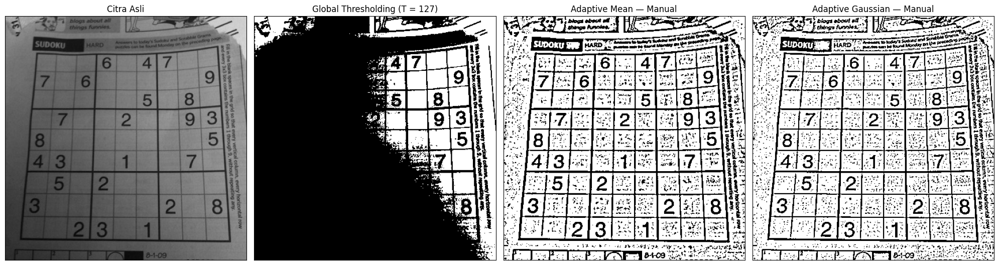

Piksel sama dgn OpenCV (mean): 97.64 %


In [ ]:
def box_mean(img, k):
    r = k // 2
    H, W = img.shape
    p = np.pad(img.astype(np.float64), r, mode='edge')
    ii = np.pad(p.cumsum(axis=0).cumsum(axis=1), ((1, 0), (1, 0)))   # integral image
    s = ii[k:k+H, k:k+W] - ii[0:H, k:k+W] - ii[k:k+H, 0:W] + ii[0:H, 0:W]
    return s / (k * k)

def gaussian_kernel_1d(k, sigma):
    x = np.arange(k) - k // 2
    g = np.exp(-(x ** 2) / (2 * sigma ** 2))
    return g / g.sum()

def gauss_mean(img, k, sigma):
    r = k // 2
    H, W = img.shape
    g = gaussian_kernel_1d(k, sigma)
    p = np.pad(img.astype(np.float64), r, mode='edge')
    tmp = sum(g[i] * p[:, i:i+W] for i in range(k))      # horizontal -> (H+2r, W)
    return sum(g[i] * tmp[i:i+H, :] for i in range(k))   # vertikal   -> (H, W)

def adaptive_threshold_manual(gray, metode='mean', k=11, C=2, sigma=2, maxval=255):
    T = box_mean(gray, k) if metode == 'mean' else gauss_mean(gray, k, sigma)
    T = T - C
    return np.where(gray > T, maxval, 0).astype(np.uint8)

gray_sdk = cv.imread(BASE + '/sudoku-original.jpg', cv.IMREAD_GRAYSCALE)

th_global = global_threshold(gray_sdk, 127, 255, 'BINARY')                       # global manual
th_mean   = adaptive_threshold_manual(gray_sdk, 'mean',     k=11, C=2)
th_gauss  = adaptive_threshold_manual(gray_sdk, 'gaussian', k=11, C=2, sigma=2)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
images = [gray_sdk, th_global, th_mean, th_gauss]
plt.figure(figsize=(20, 6))
for i in range(4):
    plt.subplot(1, 4, i+1); plt.imshow(images[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i]); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

# (opsional) cek kemiripan dengan OpenCV, hanya untuk verifikasi
ref_mean = cv.adaptiveThreshold(gray_sdk, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
print('Piksel sama dgn OpenCV (mean): %.2f %%' % (100 * np.mean(ref_mean == th_mean)))

### D1 – No. 5A. Otsu Thresholding manual (tanpa library) – citra Lena low contrast

95


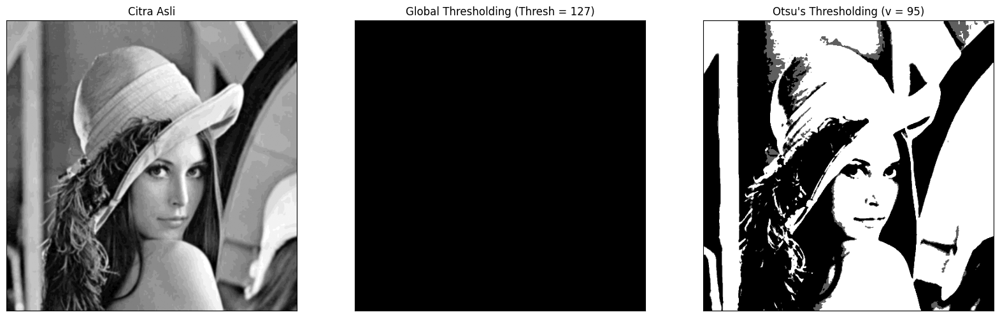

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020212/lena.jpg')
img = cv.cvtColor(cv.imread(filename), cv.COLOR_BGR2GRAY)                 # RGB -> grayscale
img = (85 + img.astype(np.float32) * (108 - 85) / 255).astype(np.uint8)   # jadikan low contrast (rentang 85-108)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:      # lewati t yang salah satu kelasnya kosong (hindari 0/0)
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

### D1 – No. 5B. Otsu pada KTP sendiri vs global threshold 127

151


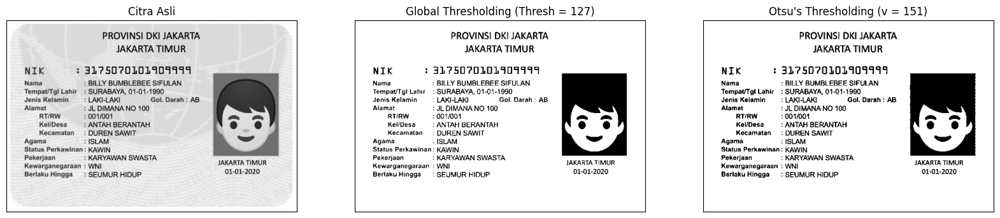

Threshold Otsu pada KTP = 151


In [ ]:
KTP_FILE = 'ktp_fulan.jpg'

ktp_gray = cv.imread(BASE + '/' + KTP_FILE, cv.IMREAD_GRAYSCALE)
if ktp_gray is None:
    raise FileNotFoundError('File tidak terbaca: ' + BASE + '/' + KTP_FILE)

thresh = 127

# Otsu memakai fungsi otsu() dari No. 5A (mengembalikan citra biner dan nilai threshold)
ktp_otsu, ktp_t = otsu(ktp_gray)

# Global threshold 127
ret, ktp_glob = cv.threshold(ktp_gray, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = 127)', "Otsu's Thresholding (v = " + str(ktp_t) + ")"]
citra3 = [ktp_gray, ktp_glob, ktp_otsu]

plt.figure(figsize=(20, 5))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

print('Threshold Otsu pada KTP =', ktp_t)

### D1 - 6A. Region Growing manual (BFS dengan `deque`)

Intensitas seed (dihaluskan): 144.70655571875804


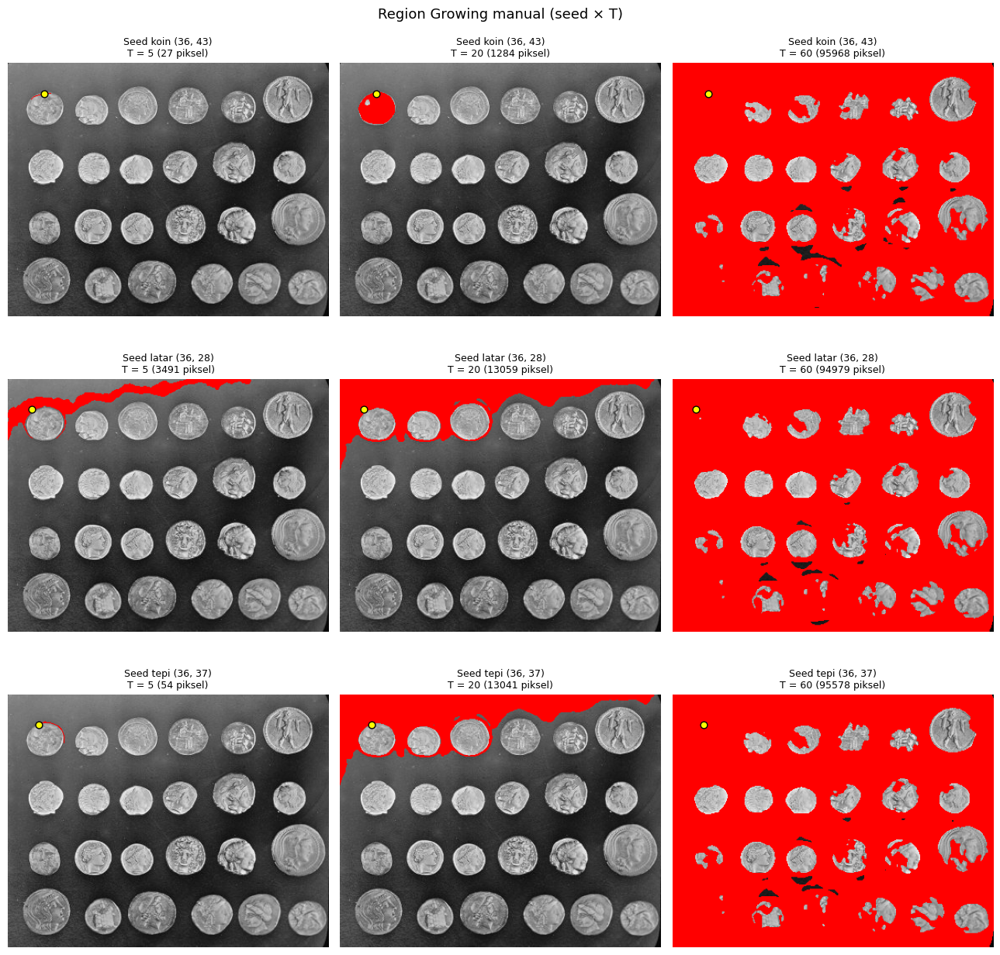

In [14]:
# Citra coins dari skimage (grayscale, 303 x 384)
coins = data.coins()

# Citra dihaluskan dulu (sigma=2), preserve_range=True agar nilainya tetap 0-255
coins_s = gaussian(coins, sigma=2, preserve_range=True)

def region_growing(gray, seed, T, connectivity=8):
    H, W = gray.shape
    r0, c0 = seed
    if connectivity == 4:
        nb = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    else:
        nb = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    mask = np.zeros((H, W), dtype=bool)
    mask[r0, c0] = True
    total, n = float(gray[r0, c0]), 1          # untuk rata-rata region yang terus diperbarui
    q = deque([(r0, c0)])
    while q:
        y, x = q.popleft()
        for dy, dx in nb:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
                if abs(float(gray[ny, nx]) - total / n) < T:    # |I(q) - mu_region| < T
                    mask[ny, nx] = True
                    total += float(gray[ny, nx]); n += 1
                    q.append((ny, nx))
    return mask

# 3 seed (baris, kolom): di dalam koin, di latar, dan tepat di tepi koin
seeds = {
    'Seed koin (36, 43)':  (36, 43),
    'Seed latar (36, 28)': (36, 28),
    'Seed tepi (36, 37)':  (36, 37),
}
T_list = [5, 20, 60]

def overlay(gray, mask):
    rgb = np.stack([gray] * 3, axis=-1).astype(np.uint8)
    rgb[mask] = [255, 0, 0]
    return rgb

def grid_hasil(fungsi, judul):
    # Grid 3x3: baris = seed, kolom = T
    plt.figure(figsize=(13, 13))
    plt.suptitle(judul, fontsize=13)
    for i, (nama, s) in enumerate(seeds.items()):
        for j, T in enumerate(T_list):
            mask = fungsi(coins_s, s, T)
            plt.subplot(3, 3, i * 3 + j + 1)
            plt.imshow(overlay(coins, mask))
            plt.scatter(s[1], s[0], s=40, c='yellow', edgecolors='black')   # posisi seed
            plt.title('%s\nT = %d (%d piksel)' % (nama, T, mask.sum()), fontsize=9)
            plt.axis('off')
    plt.tight_layout()
    plt.show()

print('Intensitas seed (dihaluskan):', coins_s[36, 43])     # harus 144.7065...
grid_hasil(lambda g, s, T: region_growing(coins_s, s, T), 'Region Growing manual (seed × T)')

### 6B. Region Growing dengan `skimage.segmentation.flood()`

Seed (baris, kolom): (36, 43) | intensitas: 159.000000
Toleransi  5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


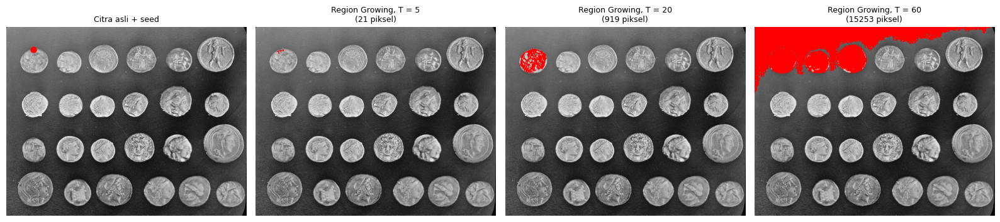

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (36, 43)
tol_list = [5, 20, 60]

print('Seed (baris, kolom):', seed, '| intensitas: %.6f' % gray[seed])

hasil = {}
for tol in tol_list:
    region = flood(
        gray,
        seed_point=seed,
        tolerance=tol,
        connectivity=1
    )
    hasil[tol] = region
    print('Toleransi %2d: %d piksel' % (tol, region.sum()))

def overlay(gray, mask):
    rgb = np.stack([gray] * 3, axis=-1).copy()
    rgb[mask] = [255, 0, 0]
    return rgb

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.scatter(seed[1], seed[0], s=40, c='red')
plt.title('Citra asli + seed', fontsize=9); plt.axis('off')

for i, tol in enumerate(tol_list):
    plt.subplot(1, 4, i + 2)
    plt.imshow(overlay(gray, hasil[tol]))
    plt.title('Region Growing, T = %d\n(%d piksel)' % (tol, hasil[tol].sum()), fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

### D1 – No. 7. Segmentasi warna KTP hanya warna biru

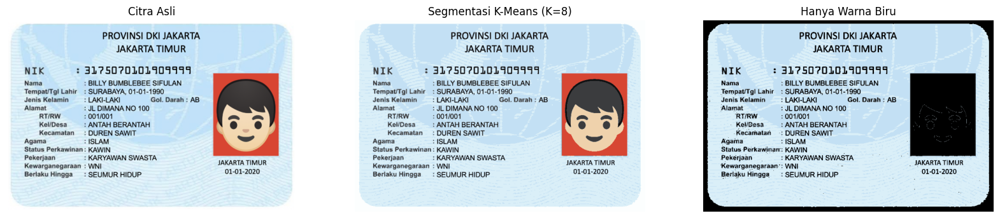

Warna pusat cluster (RGB):
 [[218 239 248]
 [ 59  60  62]
 [215  70  51]
 [195 224 244]
 [135 147 155]
 [239 210 172]
 [ 15  15  16]
 [252 254 254]]
Persentase piksel biru: 77.9 %


In [16]:
from sklearn.cluster import KMeans

ktp_bgr = cv.imread(BASE + '/' + KTP_FILE)
ktp_rgb = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)

# --- (1) K-Means, K = 8
K = 8
Z = ktp_rgb.reshape((-1, 3)).astype(np.float32)
rng = np.random.default_rng(42)
sampel = Z[rng.choice(len(Z), size=min(40000, len(Z)), replace=False)]
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(sampel)
labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)
seg_rgb = centers[labels].reshape(ktp_rgb.shape)

# --- (2) HSV dan (3) mask warna biru
hsv = cv.cvtColor(seg_rgb, cv.COLOR_RGB2HSV)
H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
hanya_biru = np.where(kelompok_biru[..., None], seg_rgb, 0).astype(np.uint8)

plt.figure(figsize=(20, 5))
for i, (im, jd) in enumerate([(ktp_rgb, 'Citra Asli'), (seg_rgb, f'Segmentasi K-Means (K={K})'), (hanya_biru, 'Hanya Warna Biru')]):
    plt.subplot(1, 3, i+1); plt.imshow(im); plt.title(jd); plt.axis('off')
plt.show()
print('Warna pusat cluster (RGB):\n', centers)
print('Persentase piksel biru: %.1f %%' % (100 * kelompok_biru.mean()))

D2. Tugas Kelompok

In [21]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [26]:
import os, re, glob, difflib
import numpy as np, pandas as pd, cv2 as cv
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output

# ===== PENGATURAN (SAMA untuk semua KTP dan semua metode) =====
DAFTAR_KTP = ['KTP-A', 'KTP-B', 'KTP-C', 'KTP-D']
LEBAR    = 1200            # semua citra diseragamkan ke lebar ini
LANG     = 'ind'           # bahasa Tesseract
CONFIG   = '--psm 6'       # page segmentation mode
CONF_MIN = 60              # kotak hijau hanya untuk kata dengan confidence > 60
ADAPT_BLOCK, ADAPT_C = 31, 10

# ===== 10 KATA/ANGKA ACUAN per KTP (WAJIB diisi sesuai tulisan asli di tiap KTP) =====
# Pilih yang terlihat jelas. Di bawah ini hanya contoh awal, silakan ganti per KTP.
_contoh = ['PROVINSI', 'JAKARTA', 'SURABAYA', 'LAKI-LAKI', 'ISLAM',
           'KAWIN', 'DUREN', 'SAWIT', 'KARYAWAN', 'SEUMUR']
ACUAN = {
    'KTP-A': list(_contoh),
    'KTP-B': list(_contoh),
    'KTP-C': list(_contoh),
    'KTP-D': list(_contoh),
}

def cari_file(kode):
    daftar = [f for f in sorted(glob.glob(BASE + '/' + kode + '.*'))
              if f.lower().endswith(('.jpeg', '.jpg'))]
    if not daftar:
        raise FileNotFoundError('File ' + kode + ' tidak ditemukan di ' + BASE)
    return daftar[0]

def siapkan_citra(kode):
    bgr = cv.imread(cari_file(kode))
    skala = LEBAR / bgr.shape[1]
    bgr = cv.resize(bgr, (LEBAR, int(bgr.shape[0] * skala)), interpolation=cv.INTER_CUBIC)
    rgb  = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)          # grayscale dulu untuk kedua thresholding
    _, otsu_img = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adapt_img = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv.THRESH_BINARY, ADAPT_BLOCK, ADAPT_C)
    return {'Berwarna': rgb, 'Otsu': otsu_img, 'Adaptive': adapt_img}

def jalankan_ocr(im):
    teks = pytesseract.image_to_string(im, lang=LANG, config=CONFIG)
    d = pytesseract.image_to_data(im, lang=LANG, config=CONFIG, output_type=Output.DICT)
    vis = im.copy() if im.ndim == 3 else cv.cvtColor(im, cv.COLOR_GRAY2RGB)
    semua_conf = []
    for i in range(len(d['text'])):
        kata = d['text'][i].strip()
        conf = float(d['conf'][i])
        if kata == '' or conf < 0:
            continue
        semua_conf.append(conf)
        if conf > CONF_MIN:
            x, y, w, h = d['left'][i], d['top'][i], d['width'][i], d['height'][i]
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    rata = float(np.mean(semua_conf)) if semua_conf else 0.0
    return {'teks': teks, 'vis': vis, 'conf': rata}

# Penilaian: cocok jika seluruh huruf/angka sama dengan acuan (abaikan huruf besar/kecil & spasi tepi)
def cocok(acuan, teks):
    a = re.sub(r'\s+', ' ', acuan.strip().lower())
    t = re.sub(r'\s+', ' ', teks.lower())
    return re.search(r'(?<![0-9a-z])' + re.escape(a) + r'(?![0-9a-z])', t) is not None

def terbaca_sebagai(acuan, teks):
    if cocok(acuan, teks):
        return acuan
    tokens = [x.strip(':;,.|') for x in teks.split()]
    m = difflib.get_close_matches(acuan, tokens, n=1, cutoff=0.5)   # kata OCR paling mirip
    return m[0] if m else '(tidak terbaca)'

METODE = ['Berwarna', 'Otsu', 'Adaptive']
data_citra, data_ocr = {}, {}
for kode in DAFTAR_KTP:
    data_citra[kode] = siapkan_citra(kode)
    data_ocr[kode] = {m: jalankan_ocr(data_citra[kode][m]) for m in METODE}
    print(kode, 'selesai | confidence:',
          {m: round(data_ocr[kode][m]['conf'], 1) for m in METODE})

KTP-A selesai | confidence: {'Berwarna': 38.2, 'Otsu': 46.3, 'Adaptive': 24.7}
KTP-B selesai | confidence: {'Berwarna': 57.8, 'Otsu': 40.1, 'Adaptive': 31.3}
KTP-C selesai | confidence: {'Berwarna': 35.9, 'Otsu': 73.5, 'Adaptive': 23.6}
KTP-D selesai | confidence: {'Berwarna': 46.9, 'Otsu': 41.1, 'Adaptive': 25.5}


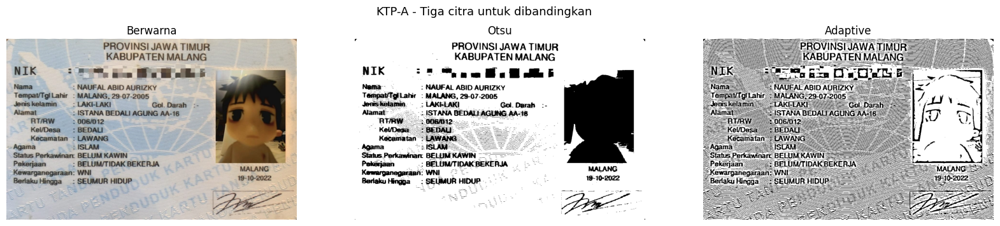

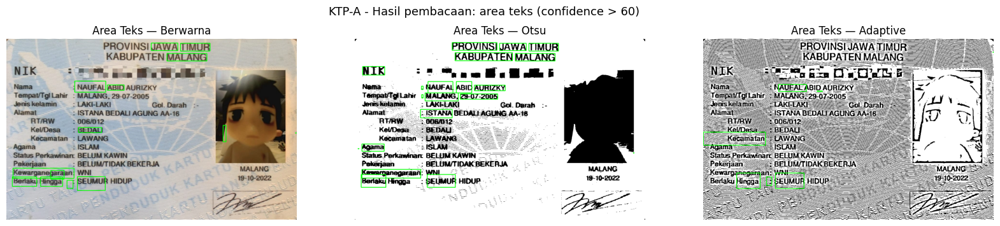

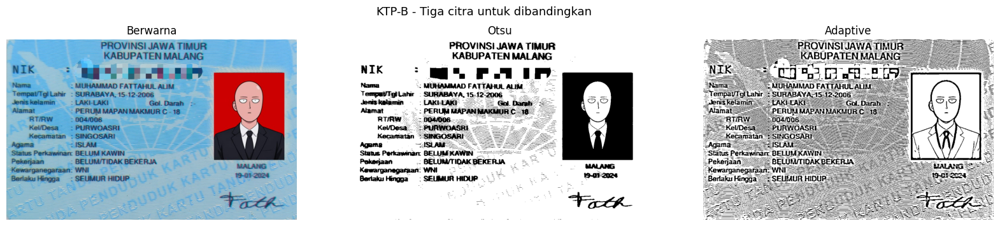

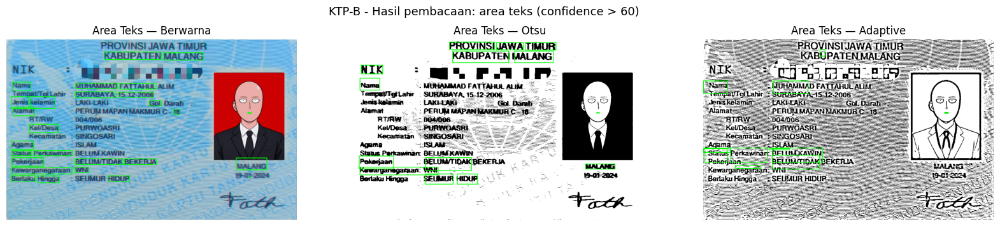

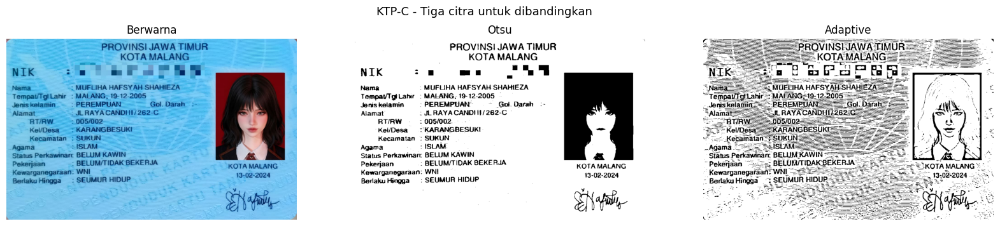

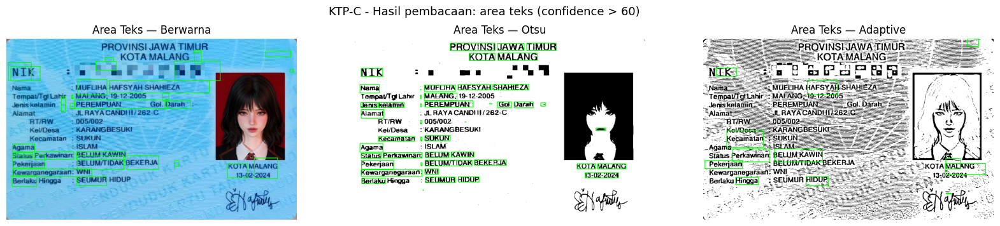

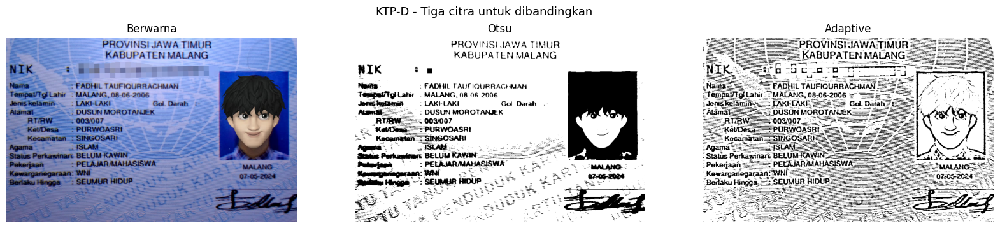

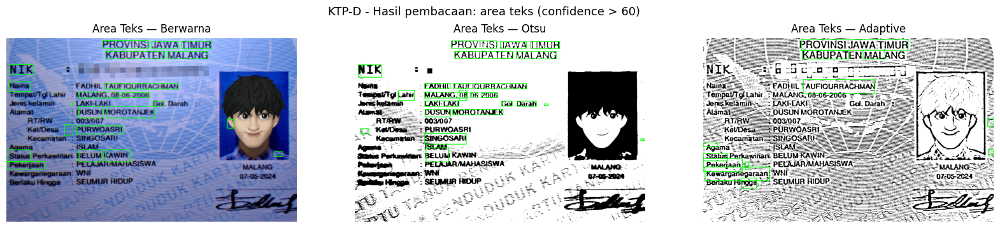

In [27]:
for kode in DAFTAR_KTP:
    plt.figure(figsize=(20, 4))
    plt.suptitle(kode + ' - Tiga citra untuk dibandingkan', fontsize=13)
    for i, m in enumerate(METODE):
        plt.subplot(1, 3, i+1)
        plt.imshow(data_citra[kode][m], cmap=None if m == 'Berwarna' else 'gray')
        plt.title(m); plt.axis('off')
    plt.show()

    plt.figure(figsize=(20, 4))
    plt.suptitle(kode + ' - Hasil pembacaan: area teks (confidence > %d)' % CONF_MIN, fontsize=13)
    for i, m in enumerate(METODE):
        plt.subplot(1, 3, i+1)
        plt.imshow(data_ocr[kode][m]['vis'])
        plt.title('Area Teks — ' + m); plt.axis('off')
    plt.show()

In [28]:
for kode in DAFTAR_KTP:
    for m in METODE:
        print('=' * 10, kode, '|', m.upper(), '=' * 10)
        print(data_ocr[kode][m]['teks'].strip())
        print()

========== KTP-A | BERWARNA ==========
5  — PROVINSI JAWA TIMUR :
KABUPATEN MALANG
NIK aa ia Mamah 3
Nama — ——: NAUFAL ABID AUREZKY
——— Kel/Desa—— BEDAH AAA AAA 5 1 5
Kecamatan LAWANG —————— |
Agama SAM :
Pekagaan—— — BELOMANDAKBEKERIA MALANG
Kewarganegaraan garaan: WNI —— 3 3 Be 1910-2022
Berlaku Hingga — SEUMUR HIDUP — —— — — AP 5

========== KTP-A | OTSU ==========
PROVINSI JAWA TIMUR
(... KABUPATEN MALANG
NIK Pa aa BB Mahi
Nama : NAUFAL ABID AURIZKY
Tempat'tgkl ahir : MALANG, 29-07-2005
Alamat ..55. ISTANA BEDALEAGDNG AA:
BPM 200m. NN
. Agama Ae aa |
Kewarganegaraan: WNI“ - OT . Bapa NG
Berlaku Hingga: SEUMUR HIDUP. Ak 6-2022

========== KTP-A | ADAPTIVE ==========
“Pe SP PROVINSIJAWATIMURE
Ts SF - SS —-—— $
“Se 2 KABUPATENMALANGEP
PA ea.
ee aa ea naa
Nama —— 2: NAUFAL ABID AURPKy 2 ——— —|x Er
Tamputgtam MAANG:28072 Tgilahic MALANG-29072005 2” 1/ yo. MN
AT na Ai Yan HT
aa EEAKP-—-——— Gol-Dat—-— . am :
RU AA NM “UII
EA Pe 4 | ? ES
“- Kelue E-
AA: AAA 555 “MH
Kecamatan LAWANG S
EF Ag

# Pertanyaan 1

Citra hasil segentasi otsu menghasilkan pembacaan yang paling bisa terbaca

## Pengaturan percobaan
- Citra: 4 KTP, lebar disamakan 1200 px, masing-masing 10 kata acuan (total 40 item per metode)
- Tesseract: `lang='ind'`, `--psm 6`
- Otsu: `cv.THRESH_BINARY + cv.THRESH_OTSU` pada grayscale
- Adaptive: `ADAPTIVE_THRESH_GAUSSIAN_C`, block size 31, C = 10

## Bukti dari tabel

| Citra masukan OCR | Item terbaca tepat (dari 40) | Kecocokan (%) | Rata-rata confidence |
|---|---|---|---|
| Berwarna asli | 22 | 55,0% | 44,7 |
| Segmentasi Otsu | **25** | **62,5%** | **50,2** |
| Segmentasi Adaptive | 12 | 30,0% | 26,3 |

Rincian per KTP (item tepat dari 10):

| KTP | Berwarna | Otsu | Adaptive |
|---|---|---|---|
| A | 6 | 5 | 3 |
| B | 6 | 6 | 1 |
| C | 5 | **8** | 6 |
| D | 5 | 6 | 2 |
| **Total** | 22 | **25** | 12 |

## Penjelasan
Otsu paling tepat karena mendapat 25 dari 40 item (62,5%), unggul dari citra berwarna (55%) dan jauh di atas Adaptive (30%). Hasil terbaiknya ada pada KTP-C yaitu 8 dari 10 item benar dengan confidence 73,5.

Namun Otsu tidak unggul di semua KTP, pada KTP-A citra berwarna lebih baik (6 lawan 5), dan pada KTP-B keduanya seri (6 lawan 6). Jadi Otsu terbaik secara rata-rata, bukan mutlak untuk setiap citra.

# Pertanyaan 2

Kesalahan berikut diambil dari hasil `image_to_string()` pada percobaan KTP (teks sebenarnya dibaca dari gambar KTP).

## 1. Huruf tertukar / salah baca

| KTP | Metode | Teks sebenarnya | Hasil OCR |
|---|---|---|---|
| A | Berwarna | ISLAM | SAM |
| B | Berwarna | ISLAM | HSEAM |
| C | Berwarna | ISLAM | SIA |
| B | Berwarna | PURWOASRI | PURYOASRI (W terbaca Y) |
| A | Berwarna | BEDALI | BEDAH |
| B | Otsu | MAKMUR | MARMERI |

## 2. Angka salah
- KTP-C (Otsu): RT/RW `005/002` terbaca dengan angka 9 menggantikan 0 (`905/902`).
- KTP-D (Otsu): tanggal lahir dengan tanda hubung hilang dan satu angka berubah (`08-06-2006` menjadi `08 96 2006`).
- KTP-B (Otsu): tanda hubung pada tanggal hilang (`15-12-2006` menjadi `15122006`).

## 3. Teks tidak terbaca / baris hilang
- KTP-A: `LAKI-LAKI` tidak terbaca di ketiga citra (berwarna, Otsu, Adaptive).
- KTP-D: baris Kewarganegaraan dan Berlaku Hingga (WNI, SEUMUR HIDUP) hilang pada citra berwarna dan Otsu.
- KTP-B (Otsu): baris Kecamatan dan Kel/Desa (SINGOSARI, PURWOASRI) tidak terbaca.

## 4. Kata menyatu dan teks sampah
- `PROVINSI JAWA TIMUR` terbaca `PROVINSIJAWATIMUR` (spasi hilang), terutama pada Adaptive.
- Citra Adaptive menghasilkan teks sampah seperti `AAA`, `PA`, `SS` yang bukan bagian dari KTP.

# Pertanyaan 3

Tidak, Karena segmentasi hanya membantu jika latar benar-benar hilang tanpa merusak huruf

## Perbandingan terhadap citra berwarna (item tepat dari 10)

| KTP | Berwarna | Otsu | Perubahan Otsu | Adaptive | Perubahan Adaptive |
|---|---|---|---|---|---|
| A | 6 | 5 | turun (−1) | 3 | turun (−3) |
| B | 6 | 6 | sama | 1 | turun (−5) |
| C | 5 | 8 | naik (+3) | 6 | naik (+1) |
| D | 5 | 6 | naik (+1) | 2 | turun (−3) |
| **Total (dari 40)** | 22 (55%) | 25 (62,5%) | **+3** | 12 (30%) | **−10** |

## Penjelasan
- Otsu: membantu pada 2 KTP (C dan D), seri pada 1 (B), dan menurun pada 1 (A). Peningkatan totalnya kecil (55% menjadi 62,5%) dan tidak konsisten.
- Adaptive: menurunkan ketepatan pada 3 dari 4 KTP dan total turun dari 55% menjadi 30%. Pada pengaturan block 31 dan C 10, pola latar KTP justru diperkuat menjadi garis dan bintik hitam yang dibaca sebagai teks sampah.
- Pada KTP-A, citra asli memiliki baris `Kecamatan LAWANG` yang terbaca baik, tetapi hilang setelah Otsu karena pencahayaan tidak merata (ada pantulan cahaya), sehingga satu ambang global kurang cocok.

# Pertanyaan 4

## Ciri latar KTP pada percobaan
- Latar biru muda dengan **gradasi** warna
- Pola garis halus dan peta dunia
- Watermark diagonal "KARTU TANDA PENDUDUK"
- Foto berwarna (latar merah atau biru) di sisi kanan
- Pada KTP-A terdapat pantulan cahaya, dan pada KTP-D watermark paling kuat

## Pengaruh pada tiap kondisi

| Kondisi | Efek pada OCR | Bukti dari percobaan |
|---|---|---|
| **Citra berwarna** | Teks gelap pada latar biru memiliki kontras rendah dan terganggu pola latar | Confidence rendah (35,9–57,8); beberapa baris hilang (KTP-D: baris Kewarganegaraan dan Berlaku Hingga); kata menyatu seperti `PROVINSIJAWA HMUR` |
| **Otsu** | Latar terang menjadi putih bersih, teks tetap hitam; tetapi watermark kuat dan foto gelap ikut hitam | Teks lebih bersih (KTP-C: 8/10, confidence 73,5); watermark KTP-D tetap muncul dan blok foto hitam bisa dibaca sebagai noise |
| **Adaptive** | Setiap garis halus pada pola latar dianggap objek, sehingga latar penuh garis dan bintik | Teks sampah (`AAA`, `PA`, `SS`), baris menyatu, kecocokan hanya 30% dan confidence 26,3 |

## Penjelasan
Pola latar yang berulang dan padat memiliki frekuensi serupa dengan goresan huruf. Pada Adaptive, ambang dihitung dari jendela kecil (31 × 31), sehingga variasi lokal kecil dari pola latar pun melewati ambang dan menjadi piksel hitam. Selain itu, `--psm 6` memaksa Tesseract menganggap seluruh area sebagai blok teks, sehingga garis-garis tersebut ikut dibaca sebagai huruf.

Latar bergradasi dan pencahayaan tidak merata juga menyulitkan satu ambang global, seperti yang terjadi pada KTP-A.

# Pertanyaan 5

Secara gabungan iya dengan Otsu tertinggi di antara keduanya, tetapi per KTP tidak selalu. Confidence bukan ukuran yang bisa diandakan

## Data gabungan

| Metode | Rata-rata confidence | Kecocokan |
|---|---|---|
| Berwarna | 44,7 | 55,0% |
| Otsu | **50,2** | **62,5%** |
| Adaptive | 26,3 | 30,0% |

Pada data gabungan, urutan confidence (Otsu, Berwarna, Adaptive) sama dengan urutan kecocokan.

## Data per KTP (confidence / kecocokan)

| KTP | Berwarna | Otsu | Adaptive | Confidence tertinggi | Kecocokan tertinggi | Sama? |
|---|---|---|---|---|---|---|
| A | 38,2 / 60% | 46,3 / 50% | 24,7 / 30% | Otsu | Berwarna | Tidak |
| B | 57,8 / 60% | 40,1 / 60% | 31,3 / 10% | Berwarna | Berwarna dan Otsu (seri) | Sebagian |
| C | 35,9 / 50% | 73,5 / 80% | 23,6 / 60% | Otsu | Otsu | Ya |
| D | 46,9 / 50% | 41,1 / 60% | 25,5 / 20% | Berwarna | Otsu | Tidak |

## Penjelasan
- KTP-A: Otsu confidence-nya lebih tinggi (46,3 lawan 38,2), tetapi kecocokannya lebih rendah (50% lawan 60%).
- KTP-B: citra berwarna confidence-nya jauh lebih tinggi (57,8 lawan 40,1), namun kecocokan keduanya sama (60%).
- KTP-D: citra berwarna confidence-nya lebih tinggi (46,9 lawan 41,1), tetapi kecocokannya lebih rendah dari Otsu (50% lawan 60%).
- Hanya KTP-C yang urutannya konsisten.

Confidence adalah tingkat keyakinan Tesseract terhadap tebakannya sendiri, bukan kebenarannya terhadap tulisan asli. Rata-rata confidence juga dihitung dari semua kata yang terdeteksi, termasuk noise, sehingga bisa naik atau turun tanpa berkaitan dengan ketepatan pada kata acuan. Karena itu kecocokan harus dinilai langsung terhadap teks acuan.